In [356]:
from tensorflow import keras
from tensorflow.keras.layers import SimpleRNN, LSTM, Embedding, Dense, Dropout, Input
import pandas as pd
import kagglehub
from pathlib import Path
import tensorflow as tf

In [357]:
Tx = 30
config = {
    "model": {
        "hidden_size": 256,
        "dropout": 0.2,
        "input_shape": (Tx,4),
        "sequence_length": Tx,
    },
    "training": {
        "batch_size": 32,
        "num_epochs": 500,
        "learning_rate": 0.001,
    },
}

In [358]:
path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")

In [359]:
path = Path(path)
files = list(path.glob('*.csv'))
df = []
for file in files:
    df.append(pd.read_csv(file))

In [360]:
training_data = df[1].drop(columns=["date"])
test_data = df[0].drop(columns=["date"])

print(f"columns: {training_data.columns}")
print(training_data.shape)
print(test_data.shape)
training_data.head()

columns: Index(['meantemp', 'humidity', 'wind_speed', 'meanpressure'], dtype='object')
(1462, 4)
(114, 4)


,meantemp,humidity,wind_speed,meanpressure
0,10.000000,84.500000,0.000000,1015.666667
1,7.400000,92.000000,2.980000,1017.800000
2,7.166667,87.000000,4.633333,1018.666667
3,8.666667,71.333333,1.233333,1017.166667
4,6.000000,86.833333,3.700000,1016.500000


In [361]:
mean = training_data.mean(axis=0)
std = training_data.std(axis=0)

training_data_norm = (training_data - mean) / std
test_data_norm = (test_data - mean) / std

print("Mean:", mean)
print("Std:", std)

Mean: meantemp          25.495521
humidity          60.771702
wind_speed         6.802209
meanpressure    1011.104548
dtype: float64
Std: meantemp          7.348103
humidity         16.769652
wind_speed        4.561602
meanpressure    180.231668
dtype: float64


In [362]:
import numpy as np

# Using tf.keras.utils.timeseries_dataset_from_array

BATCH_SIZE = config['training']['batch_size']
SEQ_LENGTH = config['model']['sequence_length']

# Use Normalized Data
values = training_data_norm.values 

dataset_train = keras.utils.timeseries_dataset_from_array(
    data=values[:-1], 
    targets=values[SEQ_LENGTH:], 
    sequence_length=SEQ_LENGTH,
    sequence_stride=1,
    shuffle=True,
    batch_size=BATCH_SIZE,
)

print(f"Training Dataset created. Element spec: {dataset_train.element_spec}")

Training Dataset created. Element spec: (TensorSpec(shape=(None, None, 4), dtype=tf.float64, name=None), TensorSpec(shape=(None, 4), dtype=tf.float64, name=None))


In [363]:
def temprature_forecast(input_shape):
    inputs = Input(shape=input_shape)
    x = LSTM(config['model']['hidden_size'], return_sequences=False)(inputs)
    x = Dropout(config['model']['dropout'])(x)
    outputs = Dense(4)(x) # Predicting 4 features
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

model = temprature_forecast(config['model']['input_shape'])
model.summary()
model.compile(optimizer='adam', loss='mse')


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_39 (InputLayer)     │ (None, 30, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_26 (LSTM)                  │ (None, 256)            │       267,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,292 (1.02 MB)

 Trainable params: 268,292 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [364]:
history = model.fit(dataset_train, epochs=config['training']['num_epochs'])

Epoch 1/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.6132
Epoch 2/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5602
Epoch 3/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5487
Epoch 4/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5363
Epoch 5/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5308
Epoch 6/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5239
Epoch 7/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5208
Epoch 8/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5162
Epoch 9/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5116
Epoch 10/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5125
Epoch 11/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5070
Epoch 12/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5082
Epoch 13/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5061
Epoch 14/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5010
Epoch 15/500
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - lo

Making predictions on test set...
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


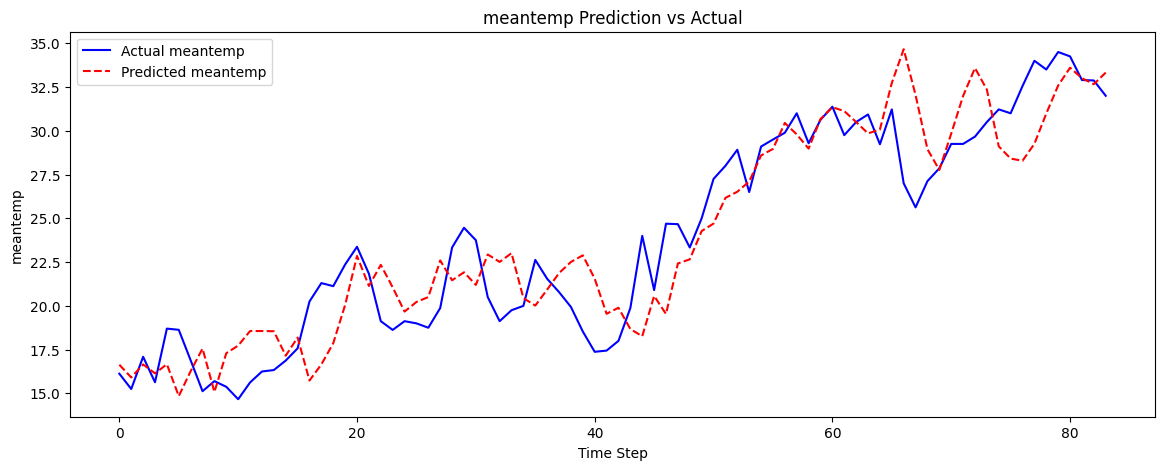

In [365]:
import matplotlib.pyplot as plt

values_test = test_data_norm.values
dataset_test = keras.utils.timeseries_dataset_from_array(
    data=values_test[:-1],
    targets=values_test[SEQ_LENGTH:],
    sequence_length=SEQ_LENGTH,
    sequence_stride=1,
    shuffle=False,
    batch_size=BATCH_SIZE,
)

print("Making predictions on test set...")
predictions_norm = model.predict(dataset_test)


y_test_norm = []
for X, y in dataset_test:
    y_test_norm.append(y.numpy())
y_test_norm = np.concatenate(y_test_norm, axis=0)

# Shape is (N, 4). mean and std are (4,)
predictions_real = (predictions_norm * std.values) + mean.values
y_test_real = (y_test_norm * std.values) + mean.values

feature_index = 0 # 0=meantemp, 1=humidity, 2=wind_speed, 3=meanpressure
feature_name = training_data.columns[feature_index]

plt.figure(figsize=(14, 5))
plt.plot(y_test_real[:, feature_index], label=f'Actual {feature_name}', color='blue')
plt.plot(predictions_real[:, feature_index], label=f'Predicted {feature_name}', color='red', linestyle='--')
plt.title(f'{feature_name} Prediction vs Actual')
plt.xlabel('Time Step')
plt.ylabel(feature_name)
plt.legend()
plt.show()

In [371]:
model.save("multivariate_time_series_forecasting.keras")